# QProgram basics: space-time ZX-diagrams of a quantum program

A `QProgram` is a quantum program built **stage by stage** on a hardware layout. A stage is a PyZX `Circuit` (a syndrome-extraction round, a logical gate, a single gate, …) or a permutation of the qubits over the hardware topology. Stages run one after the other; inside a stage the gates are scheduled as soon as possible by `pyzx.spacetime`. The program's **master graph** is one ZX-diagram in which every spider knows

* `timestep` and `delay` — when its gate starts and how long it takes (from `pyzx.spacetime`),
* `stage` — which stage created it,
* `logical_qubit` — the circuit qubit it acts on, while its `qubit` coordinate is the **physical wire** it sits on.

This notebook shows how to build a program, look at it in 1+1D and 2+1D, group stages into blocks (*level-up*) and cut the sub-diagram of any stage or block out for reasoning with PyZX.

In [1]:
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import HAD, CNOT, T, S, Measurement, Reset
from zxqec.qprogram import QProgram
from zxqec.spacetime import Topology, draw_web, draw_program_web, draw_program_3d, get_stage, get_logical_qubit

def circuit(*gates, qubits=3):
    c = Circuit(qubits)
    for g in gates:
        c.add_gate(g)
    return c

## 1. Stages and the master graph

Four small stages on three qubits. `gate_durations` is passed on to PyZX's scheduler: here a `CNOT` takes two ticks, everything else is instantaneous.

In [2]:
stages = [
    circuit(HAD(0), HAD(1), HAD(2), CNOT(0, 1)),
    circuit(T(2), CNOT(1, 2)),
    circuit(HAD(0), S(1)),
    circuit(HAD(1), CNOT(2, 0)),
]
p = QProgram(3, gate_durations={"CNOT": 2})
for i, c in enumerate(stages):
    p.add_circuit(c, name=f"stage {i}")

g = p.graph()                    # the master graph: a plain pyzx GraphS
print("ticks occupied by each stage:", [(st.name, st.ticks) for st in p.stages])
print("space-time metrics:", p.metrics())
draw_web(g)

ticks occupied by each stage: [('stage 0', (0, 2)), ('stage 1', (3, 5)), ('stage 2', (6, 6)), ('stage 3', (7, 8))]
space-time metrics: {'num_timesteps': 6, 'time_depth': 9, 'spacetime_volume': 19, 'total_delay': 12}


The master graph is the whole circuit — stages are just a bookkeeping layer on top. PyZX cannot tell the difference:

In [3]:
whole = stages[0].copy()
for c in stages[1:]:
    whole.add_circuit(c)
print("master graph == concatenated circuit:", zx.compare_tensors(g, whole.to_graph(), preserve_scalar=False))

master graph == concatenated circuit: True


## 2. Looking at it on a time axis

`zx.draw` is PyZX's interactive d3 view (drag spiders, wheel to zoom). `draw_web` is the same view with the schedule made visible: every spider sits at its **timestep** along the horizontal axis (PyZX's own layout uses an unrelated row index), so the length of a wire is the time it spans, `t` above a spider is its timestep, and a wire whose earlier spider has a non-zero delay is a squiggle with one wiggle per tick, labelled `Δ<delay>` — the squiggles follow the spiders when you drag them. `draw_program_web` adds the shading of the blocks of a level (`level=0`: one shade per stage). (`zx.draw_matplotlib(g, show_time=True)` and `draw_program` are the static matplotlib equivalents.)

In [4]:
draw_program_web(p, level=0)

## 3. Level-up: grouping stages into blocks

Level 0 has one block per stage. `level_up(level, start, end)` wraps a range of consecutive blocks into one and creates the next level. Every block has a circuit (its stage circuits concatenated) and a **sub-diagram** cut out of the master graph.

In [5]:
lvl = p.level_up(0, 1, 2, name="middle part")
print(p.describe_level(lvl))
draw_program_web(p, level=lvl)

Level 1 (3 blocks):
  Block 0 'stage 0': [stage 0]
  Block 1 'middle part': [stage 1, stage 2]
  Block 2 'stage 3': [stage 3]


In [6]:
block = p.block_graph(lvl, 1)                         # the sub-diagram of the "middle part" block
print("inputs", block.inputs(), "outputs", block.outputs())
print("block sub-diagram == its circuit:", zx.compare_tensors(block, p.block_circuit(lvl, 1).to_graph(), preserve_scalar=False))
draw_web(block)

inputs (7, 6, 5) outputs (9, 10, 8)
block sub-diagram == its circuit: True


The sub-diagram is a valid ZX-diagram on all three qubits (a qubit the block does not touch becomes an identity wire), with the Hadamard of `stage 3` correctly left *outside* — an edge belongs to the gate that created it. Anything PyZX offers applies to it:

In [7]:
h = block.copy()
zx.full_reduce(h)
zx.draw(h)

Blocks that are not adjacent can be merged when everything in between acts on other qubits — the later block is slid next to the earlier one, which does not change the program:

In [8]:
q = QProgram(3)
q.add_circuit(circuit(HAD(0)), name="H0")
q.add_circuit(circuit(T(2)), name="T2")
q.add_circuit(circuit(CNOT(0, 1)), name="CNOT01")
merged = q.merge_blocks(0, 0, 2)                      # H0 and CNOT01 around T2, which lives on qubit 2
print(q.describe_level(merged))
print("merged block == H0;CNOT01:", zx.compare_tensors(q.block_graph(merged, 0), circuit(HAD(0), CNOT(0, 1)).to_graph(), preserve_scalar=False))
print("refused when qubits overlap:", p.merge_blocks(0, 0, 3))

Level 1 (2 blocks):
  Block 0: [H0, CNOT01]
  Block 1 'T2': [T2]
merged block == H0;CNOT01: True
refused when qubits overlap: None


## 4. Permutations on a topology

Stage circuits are written on **logical** qubits. A permutation stage moves logical qubits to other physical wires; as a map on logical qubits the program is unchanged, but the spiders of later stages sit on their new wires. With a `Topology`, `check_topology=True` only accepts a layer of disjoint swaps along hardware edges under the *current* mapping.

In [9]:
line = Topology.line(3)                               # 0 - 1 - 2
r = QProgram(3, topology=line)
r.add_circuit(stages[0], name="prepare")
try:
    r.add_permutation([2, 1, 0], check_topology=True)  # wires 0 and 2 are not adjacent
except ValueError as e:
    print("rejected:", e)
r.add_permutation([1, 0, 2], check_topology=True, name="swap 0,1")
r.add_circuit(stages[1], name="after")
print("logical -> physical after the swap:", r.mapping)
draw_program_web(r, level=0)

rejected: swap (0, 2) is not along an edge of the topology (physical wires 0, 2)
logical -> physical after the swap: (1, 0, 2)


In [10]:
print("program with the swap == prepare;after on logical qubits:",
      zx.compare_tensors(r.graph(), circuit(*stages[0].gates, *stages[1].gates).to_graph(), preserve_scalar=False))

program with the swap == prepare;after on logical qubits: True


The permutation is a **stage of its own** (here stage 1, between "prepare" and "after"), with its own block at level 0. The `Stage` object records the permutation, the mapping before and after it and the tick it occupies; its circuit is empty, because on logical qubits a permutation is the identity. In the master graph the stage consists of one phase-free Z spider per wire, tagged with the stage and the logical qubit and placed on the qubit's *new* physical wire — that is where the wires cross.

In [11]:
from pyzx.spacetime import get_timestep
from pyzx.utils import VertexType

print("stages:", [(st.index, st.kind, st.name) for st in r.stages])
st = r.stage(1)
print("perm:", st.perm, "  mapping before:", r.mapping_at(0), " after:", st.mapping, "  ticks:", st.ticks)
print("circuit of the stage:", st.circuit)
rg = r.graph()
for v in rg.vertices():
    if get_stage(rg, v) == 1:
        print(f"  spider {v}: {VertexType(rg.type(v)).name} phase {rg.phase(v)}, logical qubit {get_logical_qubit(rg, v)}"
              f" on physical wire {rg.qubit(v)} at t={get_timestep(rg, v)}")
draw_web(r.stage_graph(1))     # the stage's own sub-diagram: an identity with a crossing

stages: [(0, 'circuit', 'prepare'), (1, 'permutation', 'swap 0,1'), (2, 'circuit', 'after')]
perm: (1, 0, 2)   mapping before: (0, 1, 2)  after: (1, 0, 2)   ticks: (2, 2)
circuit of the stage: Circuit(3 qubits, 0 bits, 0 gates)
  spider 11: Z phase 0, logical qubit 0 on physical wire 1 at t=2
  spider 13: Z phase 0, logical qubit 1 on physical wire 0 at t=2
  spider 15: Z phase 0, logical qubit 2 on physical wire 2 at t=2


## 5. Measurement rounds

A qubit measured in one stage has no output wire; a later stage may reuse it after a `Reset`, which becomes a fresh $|0\rangle$ preparation. PyZX's generated outcome variables (`m1`, `m2`, …) restart in every stage, so they are renamed `s<stage>_…` to stay distinct. Here: a $Z_0Z_1$ parity check with ancilla qubit 2, run twice with a `T` layer in between.

In [12]:
parity = circuit(Reset(2), HAD(2), CNOT(2, 0), CNOT(2, 1), HAD(2), Measurement(2))
s = QProgram(3, initial_states={2: '0'}, gate_durations={"CNOT": 2})
s.add_circuit(parity, name="round 1")
s.add_circuit(circuit(T(0), T(1)), name="T layer")
s.add_circuit(parity, name="round 2")
sg = s.graph()
print("outcome variables:", sorted(sg.var_registry.types))
print("inputs on logical qubits", [get_logical_qubit(sg, v) for v in sg.inputs()],
      "- outputs on", [get_logical_qubit(sg, v) for v in sg.outputs()])
draw_program_web(s, level=0)

outcome variables: ['s0_m2', 's2_m2']
inputs on logical qubits [0, 1] - outputs on [0, 1]


## 6. The 2+1D view

With a 2D topology every spider can be drawn at the position of its physical qubit in space, with time as the third axis. `draw_program_web3d` uses PyZX's three.js viewer: drag to orbit, wheel to zoom, and the ◀ ▶ buttons under the scene step a highlight plane through the timesteps (time runs along the viewer's `x` axis, the topology spans the other two). Below, the parity-check rounds of a 5-qubit "plus": four data qubits around an ancilla in the centre of a $3\times 3$ grid.

In [13]:
grid = Topology.grid(3, 3)
mapping = {0: 1, 1: 3, 2: 5, 3: 7, 4: 4}                 # logical 4 = ancilla, on the centre node
star = Circuit(5)
for gate in [Reset(4), HAD(4), CNOT(4, 0), CNOT(4, 1), CNOT(4, 2), CNOT(4, 3), HAD(4), Measurement(4)]:
    star.add_gate(gate)
t_layer = Circuit(5); t_layer.add_gate(T(0)); t_layer.add_gate(T(2))

plus = QProgram(5, topology=grid, mapping=mapping, initial_states={4: '0'}, gate_durations={"CNOT": 2})
plus.add_circuit(star, name="round 1")
plus.add_circuit(t_layer, name="T layer")
plus.add_circuit(star, name="round 2")
plus.level_up(0, 0, 1, name="round + T")
draw_program_web(plus, level=1)

In [14]:
draw_program_web(plus, level=1)

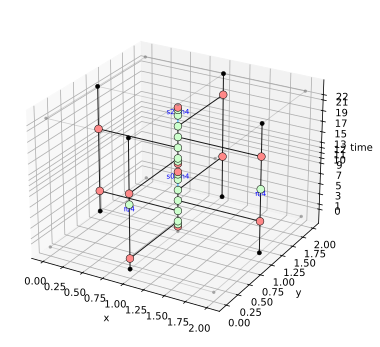

In [15]:
draw_program_3d(plus)

For scripts and static figures the same views exist with matplotlib: `draw_program` (time axis with block shading), `draw_program_3d` with named viewpoints (`view='top'` for the bird's-eye view, `'front'`, `'side'`), `draw_program_views` for several viewpoints side by side, and `examples/interactive_3d_view.py` for a rotatable window.